1: Import Libraries

In [2]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(1)

2: Set Asset Mean and Volatility

In [3]:
mu = np.array([0.08, 0.10, 0.12, 0.07]) / 252

sig = np.array([0.15, 0.20, 0.25, 0.12]) / np.sqrt(252)

print("Daily Mean Returns:", mu)
print("Daily Volatility:", sig)

Daily Mean Returns: [0.00031746 0.00039683 0.00047619 0.00027778]
Daily Volatility: [0.00944911 0.01259882 0.01574852 0.00755929]


3: Simulate 10,000 Returns

In [4]:
ret = np.random.normal(mu, sig, (10000, 252, 4))

print("Returns Shape:", ret.shape)

Returns Shape: (10000, 252, 4)


4: Calculate Portfolio Paths

In [5]:
w = np.full(4, 0.25)

portfolio_returns = ret @ w

logr = np.log1p(portfolio_returns)

paths = np.exp(logr.cumsum(axis=1))

print("Portfolio Paths Shape:", paths.shape)

Portfolio Paths Shape: (10000, 252)


5: Calculate Final Portfolio Returns

In [6]:
final_values = paths[:, -1]

portfolio_profit = final_values - 1

print("Average Final Value:", np.mean(final_values))
print("Minimum Final Value:", np.min(final_values))
print("Maximum Final Value:", np.max(final_values))

Average Final Value: 1.0965868541360364
Minimum Final Value: 0.7595234324087834
Maximum Final Value: 1.5599131474613799


6: Calculate Volatility and 95% VaR

In [7]:
volatility = np.std(portfolio_profit)

var_95 = np.percentile(portfolio_profit, 5)

print("Annual Portfolio Volatility:", volatility)
print("95% Value at Risk:", abs(var_95))
print("95% VaR (%):", abs(var_95) * 100)

Annual Portfolio Volatility: 0.10332801764976432
95% Value at Risk: 0.06416205707723861
95% VaR (%): 6.4162057077238615


# Note: Here, VaR represents the estimated loss threshold at the 95% confidence level. It is calculated using the fifth percentile of simulated annual returns.

7: Plot Portfolio Return Histogram

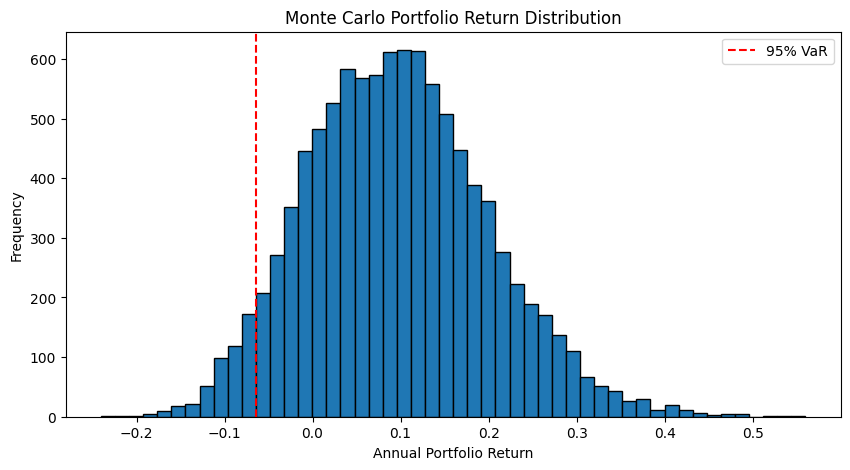

In [8]:
plt.figure(figsize=(10, 5))

plt.hist(portfolio_profit, bins=50, edgecolor='black')

plt.axvline(var_95, color='red',
            linestyle='dashed',
            label='95% VaR')

plt.title("Monte Carlo Portfolio Return Distribution")
plt.xlabel("Annual Portfolio Return")
plt.ylabel("Frequency")

plt.legend()
plt.show()

8: Plot Sample Portfolio Paths

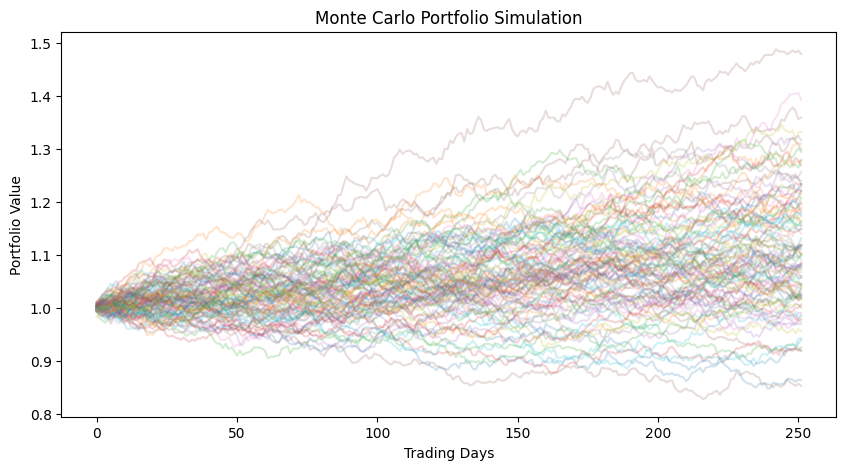

In [9]:
plt.figure(figsize=(10, 5))

plt.plot(paths[:100].T, alpha=0.2)

plt.title("Monte Carlo Portfolio Simulation")
plt.xlabel("Trading Days")
plt.ylabel("Portfolio Value")

plt.show()

Final Summary

In [10]:
print("MONTE CARLO PORTFOLIO RISK REPORT")
print("--------------------------------")

print("Total Simulations:", 10000)
print("Investment Period: 1 Year")
print("Number of Assets:", 4)
print("Portfolio Weights:", w)

print("Expected Annual Return:",
      np.mean(portfolio_profit) * 100, "%")

print("Annual Volatility:",
      volatility * 100, "%")

print("95% Value at Risk:",
      abs(var_95) * 100, "%")

MONTE CARLO PORTFOLIO RISK REPORT
--------------------------------
Total Simulations: 10000
Investment Period: 1 Year
Number of Assets: 4
Portfolio Weights: [0.25 0.25 0.25 0.25]
Expected Annual Return: 9.658685413603632 %
Annual Volatility: 10.332801764976432 %
95% Value at Risk: 6.4162057077238615 %
